# LEDGAR — final evaluation on the held-out test set (milestone m4)

> **Summary**
> - Best model on the 10 000 test clauses: DistilBERT, fully fine-tuned for 10 epochs, macro-F1 **0.827 ± 0.004**
>   over three seeds (accuracy 0.880). The TF-IDF baseline scores 0.829 (accuracy 0.877), and the paired tests find
>   **no significant difference** between the two (macro-F1 difference −0.003, 95 % interval [−0.013, +0.007];
>   McNemar p = 0.60).
> - Registered comparison (3 epochs): full fine-tuning and LoRA have the same macro-F1 (difference −0.005, interval
>   [−0.015, +0.010]), but full fine-tuning is right more often (McNemar p = 0.002). By the registered rule the
>   verdict is full fine-tuning; the hypothesis is only half confirmed.
> - After 10 epochs, full fine-tuning leads LoRA by 1.1 points, significant by the bootstrap (interval [+0.002,
>   +0.020]) though not by McNemar (p = 0.057): the production candidate is full fine-tuning, 10 epochs.
> - Its weak spots: *Applicable Laws* (F1 0.23, read as *Governing Laws*, with high confidence), the rare types
>   (macro-F1 0.76 in the tail against 0.96 in the head) and near-synonym pairs. Copies of training clauses are
>   almost always right; clauses cut at 512 tokens are not worse than the others.

Every model was chosen on validation, and every final run predicted the 10 000 test clauses once, when it was
trained. This notebook is where those test predictions are read: the final table, the comparison registered
in the README before any transformer was trained, the secondary comparisons, and where the chosen model fails.

## Setup

In [1]:
import json
import warnings
from dataclasses import replace

warnings.filterwarnings("ignore", message="IProgress not found")

import datasets
import numpy as np
import pandas as pd
import transformers
from huggingface_hub.utils import logging as hub_logging

from ledgar import data, metrics, plots, runs, stats, train_bert
from ledgar.config import Config
from ledgar.predict import run_config

transformers.logging.set_verbosity_error()
datasets.disable_progress_bars()
hub_logging.set_verbosity_error()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

cfg = Config.from_env()
RESULTS, REPORTS = cfg.path("results"), cfg.path(cfg.reports_dir)
full = data.load_ledgar(replace(cfg, n_train_per_class=None, n_eval_per_class=None))  # runs saw every clause
LABELS = data.label_names(full)
train_counts = np.bincount(full["train"]["label"], minlength=cfg.n_classes)
FINAL = {
    "lazy floor (always Governing Laws)": ["lazy"],
    "TF-IDF + logistic regression": ["tfidf"],
    "BiLSTM + GloVe": [f"lstm_seed{s}" for s in (0, 1, 2)],
    "DistilBERT, full fine-tuning": [f"bert_lr5e-5_seed{s}" for s in (0, 1, 2)],
    "DistilBERT + LoRA r=8 (q, v)": [f"lora_lr1e-3_seed{s}" for s in (0, 1, 2)],
    "DistilBERT + LoRA r=16 (q, v)": ["lora_r16_seed0"],
    "DistilBERT + LoRA r=8 (all linear)": ["lora_all_seed0"],
    "DistilBERT, full fine-tuning, 10 epochs": [f"bert_lr5e-5_ep10_seed{s}" for s in (0, 1, 2)],
    "DistilBERT + LoRA r=8 (q, v), 10 epochs": [f"lora_lr1e-3_ep10_seed{s}" for s in (0, 1, 2)],
}
FINAL = {k: [r for r in v if (RESULTS / r / "pred_test.csv").exists()] for k, v in FINAL.items()}
FINAL = {k: v for k, v in FINAL.items() if v}
test = {r: runs.load_predictions(RESULTS / r, "test") for v in FINAL.values() for r in v}
y_test = test["tfidf"]["y_true"]
assert all(
    np.array_equal(p["index"], test["tfidf"]["index"]) and np.array_equal(p["y_true"], y_test)
    for p in test.values()
)
print(cfg, "|", sum(len(v) for v in FINAL.values()), "final runs on the same", len(y_test), "test clauses")

fast_run=False | seed=0 | device=mps | precision=fp32 | batch_size=8 | grad_accum=4 | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=10 | 19 final runs on the same 10000 test clauses


## 1. How do the models compare on the test set?

Mean ± standard deviation over the seeds when there are three; trainable parameters and training time per run.
DistilBERT and LoRA appear twice: as registered (3 epochs) and in the follow-up (10 epochs).

In [2]:
rows = []
for model, names in FINAL.items():
    m = [runs.load_run(RESULTS / r) for r in names]
    val = [x["metrics"]["val"]["macro_f1"] for x in m]
    tst = [x["metrics"]["test"]["macro_f1"] for x in m]
    rows.append(
        {
            "model": model,
            "seeds": len(names),
            "trainable": m[0]["metrics"].get("trainable_params", 0),
            "minutes": f"{np.mean([x['manifest'].get('duration_s', 0) for x in m]) / 60:.1f}",
            "val macro-F1": f"{np.mean(val):.4f}" + (f" ± {np.std(val, ddof=1):.4f}" if len(val) > 1 else ""),
            "test macro-F1": f"{np.mean(tst):.4f}"
            + (f" ± {np.std(tst, ddof=1):.4f}" if len(tst) > 1 else ""),
            "test accuracy": np.mean([x["metrics"]["test"]["accuracy"] for x in m]),
        }
    )
final_table = pd.DataFrame(rows).set_index("model")
(REPORTS / "final_table.md").write_text(runs.to_markdown(final_table.round(4).reset_index()))
final_table.round(4)

,seeds,trainable,minutes,val macro-F1,test macro-F1,test accuracy
model,,,,,,
lazy floor (always Governing Laws),1,0,0.0,0.0010,0.0011,0.0582
TF-IDF + logistic regression,1,17347800,2.3,0.8265,0.8291,0.8771
BiLSTM + GloVe,3,1344684,32.6,0.7895 ± 0.0044,0.7802 ± 0.0055,0.8486
"DistilBERT, full fine-tuning",3,67030372,3.6,0.7908 ± 0.0002,0.7836 ± 0.0047,0.8673
"DistilBERT + LoRA r=8 (q, v)",3,814948,3.7,0.7841 ± 0.0008,0.7816 ± 0.0012,0.8584
"DistilBERT + LoRA r=16 (q, v)",1,962404,3.6,0.7848,0.7845,0.8580
DistilBERT + LoRA r=8 (all linear),1,1331044,5.6,0.7905,0.7867,0.8605
"DistilBERT, full fine-tuning, 10 epochs",3,67030372,11.6,0.8198 ± 0.0012,0.8270 ± 0.0036,0.8798
"DistilBERT + LoRA r=8 (q, v), 10 epochs",3,814948,11.9,0.8078 ± 0.0007,0.8144 ± 0.0005,0.8749


→ **Consequence:** at 3 epochs every neural model (BiLSTM, DistilBERT, LoRA) sits 4 to 5 points below TF-IDF on the test set.
Trained for 10 epochs, DistilBERT catches up (0.827 against 0.829) but does not pass the baseline, with four times
its parameters, a GPU and 12 minutes of training against 2 minutes on a laptop CPU. LoRA at 10 epochs reaches
0.814, 1.3 points behind full fine-tuning with 1.2 % of its trainable parameters. Validation and test rank the
models the same way and the spread between seeds stays under 0.006, so the choices made on validation did not
over-fit it.

## 2. The registered comparison: is full fine-tuning worth it over LoRA? (3 epochs)

As written in the README before any m4 run: seed 0 of each, 3 epochs, McNemar's test on per-clause correctness
and a paired bootstrap of the macro-F1 difference (1 000 resamples, 95 % interval), α = 5 %. **Rule:** if the
interval contains 0 and McNemar's p ≥ 0.05, LoRA is the production candidate; otherwise full fine-tuning is.

In [3]:
A, B = "bert_lr5e-5_seed0", "lora_lr1e-3_seed0"
main = stats.compare(
    y_test, test[A]["y_pred"], test[B]["y_pred"], n_boot=cfg.n_boot, seed=cfg.seed, n_classes=cfg.n_classes
)
(REPORTS / "comparisons").mkdir(parents=True, exist_ok=True)
(REPORTS / "comparisons" / f"{A}__vs__{B}.json").write_text(
    json.dumps({"a": A, "b": B, **main}, indent=2) + "\n"
)
bs, mc, t = main["bootstrap"], main["mcnemar"], main["contingency"]
lora_wins = (bs["low"] <= 0 <= bs["high"]) and mc["p"] >= 0.05
f1, acc = main["macro_f1"], main["accuracy"]
print(
    f"macro-F1: full {f1[0]:.4f} | LoRA {f1[1]:.4f} | difference {bs['diff']:+.4f}, "
    f"95 % interval [{bs['low']:+.4f}, {bs['high']:+.4f}]"
)
print(
    f"accuracy: full {acc[0]:.4f} | LoRA {acc[1]:.4f} | only full right b = {t['only_a']}, "
    f"only LoRA right c = {t['only_b']}, McNemar chi2 {mc['chi2']:.2f}, p = {mc['p']:.4g}"
)
print("registered verdict:", "LoRA" if lora_wins else "full fine-tuning", f"({B if lora_wins else A})")

macro-F1: full 0.7781 | LoRA 0.7826 | difference -0.0045, 95 % interval [-0.0147, +0.0098]
accuracy: full 0.8656 | LoRA 0.8582 | only full right b = 323, only LoRA right c = 249, McNemar chi2 9.32, p = 0.002271
registered verdict: full fine-tuning (bert_lr5e-5_seed0)


→ **Verdict (registered).** Macro-F1 is level: LoRA is even 0.45 point higher, well inside the interval. Accuracy is not:
of the 572 clauses on which exactly one of the two models is right, full fine-tuning is the right one 323 times
against 249 (McNemar p = 0.002). The rule chooses LoRA only if neither test finds a difference, so the registered
verdict is **full fine-tuning**. The hypothesis is half right: the macro-F1 gap is within a point and not
significant, but the two models are not equivalent. Full fine-tuning gets more clauses right overall while the
mean over types (where rare types weigh as much as frequent ones) does not move, which suggests that its extra
correct answers are mostly on frequent types.

## 2b. The same comparison after 10 epochs (follow-up)

The 3-epoch models were still learning, so both were trained for 10 epochs (decided on validation, after the
registered runs). Same tests, same rule; this comparison is the one that names the production candidate.

In [4]:
A10, B10 = "bert_lr5e-5_ep10_seed0", "lora_lr1e-3_ep10_seed0"
follow = stats.compare(
    y_test,
    test[A10]["y_pred"],
    test[B10]["y_pred"],
    n_boot=cfg.n_boot,
    seed=cfg.seed,
    n_classes=cfg.n_classes,
)
(REPORTS / "comparisons" / f"{A10}__vs__{B10}.json").write_text(
    json.dumps({"a": A10, "b": B10, **follow}, indent=2) + "\n"
)
bs, mc, t = follow["bootstrap"], follow["mcnemar"], follow["contingency"]
CANDIDATE = B10 if (bs["low"] <= 0 <= bs["high"]) and mc["p"] >= 0.05 else A10
f1, acc = follow["macro_f1"], follow["accuracy"]
print(
    f"macro-F1: full {f1[0]:.4f} | LoRA {f1[1]:.4f} | difference {bs['diff']:+.4f}, "
    f"95 % interval [{bs['low']:+.4f}, {bs['high']:+.4f}]"
)
print(
    f"accuracy: full {acc[0]:.4f} | LoRA {acc[1]:.4f} | b = {t['only_a']}, "
    f"c = {t['only_b']}, McNemar chi2 {mc['chi2']:.2f}, p = {mc['p']:.4g}"
)
print("production candidate:", CANDIDATE)

macro-F1: full 0.8259 | LoRA 0.8144 | difference +0.0114, 95 % interval [+0.0020, +0.0200]
accuracy: full 0.8786 | LoRA 0.8736 | b = 356, c = 306, McNemar chi2 3.63, p = 0.05685
production candidate: bert_lr5e-5_ep10_seed0


→ **Verdict (10-epoch follow-up).** At 10 epochs, full fine-tuning pulls ahead on macro-F1 (+1.14 points,
0.8260 against 0.8146 on seed 0, 95 % bootstrap interval [+0.0020, +0.0200], 0 outside the interval), while
per-clause disagreements narrow to 356 against 306 (McNemar p = 0.057). With more epochs full fine-tuning
learns the tail types that LoRA's rank-8 adapters miss, so `bert_lr5e-5_ep10_seed0` remains the production
candidate (`CANDIDATE`), with `lora_lr1e-3_ep10_seed0` kept as the lightweight versioned alternative.

## 3. Secondary comparisons

Same tests, between seed-0 runs: is a transformer worth its cost over the TF-IDF baseline and over the BiLSTM,
and does LoRA on every linear layer beat LoRA on the query and value projections?

In [5]:
pairs_to_test = [(CANDIDATE, "tfidf"), (CANDIDATE, "lstm_seed0"), ("lora_all_seed0", B)]
rows = []
for a, b in pairs_to_test:
    if a not in test or b not in test:
        continue
    r = stats.compare(
        y_test,
        test[a]["y_pred"],
        test[b]["y_pred"],
        n_boot=cfg.n_boot,
        seed=cfg.seed,
        n_classes=cfg.n_classes,
    )
    (REPORTS / "comparisons" / f"{a}__vs__{b}.json").write_text(
        json.dumps({"a": a, "b": b, **r}, indent=2) + "\n"
    )
    rows.append(
        {
            "A": a,
            "B": b,
            "macro-F1 A - B": r["bootstrap"]["diff"],
            "95 % low": r["bootstrap"]["low"],
            "95 % high": r["bootstrap"]["high"],
            "b (only A)": r["contingency"]["only_a"],
            "c (only B)": r["contingency"]["only_b"],
            "McNemar p": r["mcnemar"]["p"],
            "significant": r["bootstrap"]["significant"] and r["mcnemar"]["significant"],
        }
    )
pd.DataFrame(rows).round(4)

,A,B,macro-F1 A - B,95 % low,95 % high,b (only A),c (only B),McNemar p,significant
0,bert_lr5e-5_ep10_seed0,tfidf,-0.0032,-0.0132,0.0066,366,351,0.6011,False
1,bert_lr5e-5_ep10_seed0,lstm_seed0,0.0460,0.0342,0.0568,630,313,0.0000,True
2,lora_all_seed0,lora_lr1e-3_seed0,0.0040,-0.0063,0.0160,249,226,0.3128,False


→ **Consequence:** the candidate does not beat TF-IDF: the macro-F1 difference straddles zero and the 717 clauses on which
they disagree split 366 to 351 (p = 0.60). On LEDGAR a well-tuned bag of word pairs is as good as a fine-tuned
transformer. The LexGLUE benchmark reports the same on this dataset: a TF-IDF + SVM baseline at 81.4 macro-F1
against 81.8 for BERT-base (Chalkidis et al., 2022, [github.com/coastalcph/lex-glue](https://github.com/coastalcph/lex-glue)).
The transformer's advantage would have to come
from elsewhere (clauses outside the SEC filings it was trained on, or other languages), which this test set cannot
show. Against the BiLSTM the transformer is clearly better (+4.6 points, 630 against 313). LoRA on every linear
layer is not significantly better than LoRA on query and value (+0.4 point, p = 0.31).

## 4. Where does the production candidate fail?

Seed 0 of the candidate on the test set: the weakest types (with their support: three types have fewer than 10
test clauses), the most confused pairs, and macro-F1 in four slices: frequency band of the type, clauses that
also appear word for word in the training set, and clauses longer than `max_length` (cut before the model
reads their end).

In [6]:
pred = test[CANDIDATE]["y_pred"]
report = metrics.per_class_report(y_test, pred, LABELS, train_counts=train_counts)
weak = report[(report["support"] > 0) & (report["f1"] < 0.5)]
C = metrics.confusion(y_test, pred, cfg.n_classes)
confused = metrics.most_confused(C, k=10, label_names=LABELS)
print(f"{len(weak)} types with test F1 below 0.5:", ", ".join(weak["label"]))
report.head(12).round(3)

3 types with test F1 below 0.5: Applicable Laws, Assigns, Venues


,label,train_count,support,predicted,precision,recall,f1
0,Applicable Laws,352,53,34,0.294,0.189,0.230
1,Assigns,31,4,1,1.000,0.250,0.400
2,Venues,131,20,18,0.500,0.450,0.474
3,Approvals,178,26,30,0.500,0.577,0.536
4,Costs,168,15,22,0.455,0.667,0.541
5,Miscellaneous,479,79,66,0.606,0.506,0.552
6,Powers,125,13,18,0.500,0.692,0.581
7,Indemnity,271,29,22,0.682,0.517,0.588
8,Qualifications,47,5,5,0.600,0.600,0.600
9,Agreements,252,48,32,0.750,0.500,0.600


In [7]:
confused

,class_a,class_b,label_a,label_b,a_as_b,b_as_a,total
0,4,47,Applicable Laws,Governing Laws,32,20,52
1,86,99,Tax Withholdings,Withholdings,22,13,35
2,28,29,Defined Terms,Definitions,14,19,33
3,63,97,No Waivers,Waivers,16,11,27
4,2,60,Amendments,Modifications,8,15,23
5,76,98,Representations,Warranties,12,11,23
6,9,10,Authority,Authorizations,7,13,20
7,13,84,Binding Effects,Successors,6,14,20
8,38,52,Entire Agreements,Integration,7,13,20
9,49,50,Indemnifications,Indemnity,5,13,18


n  accuracy  macro_f1
                                        group                           
frequency band of the type              middle  5183    0.8472    0.8666
                                        head    4166    0.9472    0.9611
                                        tail     651    0.6897    0.7646
word-for-word copy of a training clause no      9718    0.8754    0.8223
                                        yes      282    0.9894    0.9886
longer than 512 tokens                  no      9825    0.8780    0.8252
                                        yes      175    0.9143    0.8676

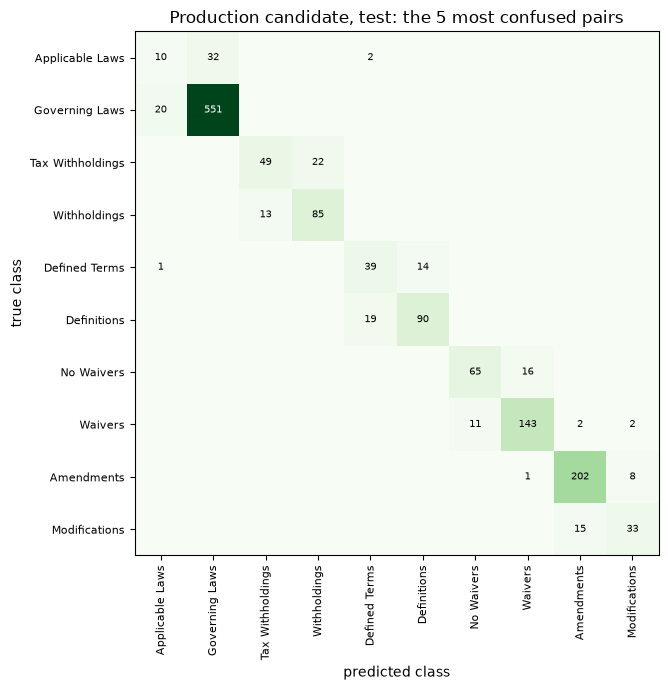

In [8]:
max_length = run_config(
    RESULTS / CANDIDATE
).max_length  # the length the candidate was trained and tested with
n_tokens = data.wordpiece_lengths(full["test"]["text"], train_bert.load_tokenizer(cfg))
seen = data.seen_in_train(full, "test")
band = data.frequency_band(train_counts)[y_test]
groups = {
    "frequency band of the type": band,
    "word-for-word copy of a training clause": np.where(seen, "yes", "no"),
    f"longer than {max_length} tokens": np.where(n_tokens > max_length, "yes", "no"),
}
slices = pd.concat(
    {
        name: metrics.f1_by_group(y_test, pred, g, cfg.n_classes).set_index("group")
        for name, g in groups.items()
    }
)
worst = list(dict.fromkeys(confused[["class_a", "class_b"]].head(5).to_numpy().ravel()))
fig = plots.plot_confusion(
    C[np.ix_(worst, worst)],
    [LABELS[k] for k in worst],
    title="Production candidate, test: the 5 most confused pairs",
    path=None if cfg.fast_run else REPORTS / "figures" / "test_confusion_pairs.png",
)
slices.round(4)

→ **Consequence:** three types fall under 0.5 F1: *Applicable Laws* (0.23 on 53 clauses, recall 0.19), *Assigns* (4 test
clauses) and *Venues* (0.47). Errors concentrate in pairs of near-synonyms (*Applicable* / *Governing Laws* 52,
*Tax Withholdings* / *Withholdings* 35, *Defined Terms* / *Definitions* 33, *No Waivers* / *Waivers* 27). Frequency
matters: macro-F1 0.96 over head types, 0.87 middle, 0.76 tail. The 282 test clauses that copy a training clause
are 99 % right against 87.5 % for the others; without them macro-F1 is 0.822, the figure to expect on unseen
contracts. Truncation is not a weakness at 512 tokens: the 175 longer clauses are right 91 % of the time.

## 5. Bias audit across contracts, parties, jurisdictions and formatting

LEDGAR has no contract-level metadata, so we derive four slices from the clause text itself
(`data.bias_slices`), joined back to the saved test predictions (`pred_test.csv` and `topk_test.npz`) by
`index`: inferred contract kind, primary party role, named jurisdiction, and ALL-CAPS conspicuous
boilerplate (> 50 % uppercase letters).

n  ...  retrieval_p10
dimension           group                               ...               
contract kind       general / unspecified         4669  ...         0.7626
                    employment / equity           2106  ...         0.6837
                    credit / loan                 1855  ...         0.7935
                    M&A / purchase                 637  ...         0.7796
                    indenture / securities         452  ...         0.7916
                    lease / license                281  ...         0.5758
party role          company / general             5124  ...         0.7637
                    employee / participant        2071  ...         0.6822
                    borrower / lender             1738  ...         0.7999
                    buyer / seller                 511  ...         0.8047
                    holder / trustee / investor    368  ...         0.7111
                    landlord / tenant / licensor   188  ...         0.5293
jurisdiction named  none named                    9243  ...         0.7479
                    New York                       358  ...         0.8123
                    Delaware                       188  ...         0.7367
                    Texas / Nevada / Florida       119  ...         0.7042
                    California                      65  ...         0.6677
                    non-US / international          27  ...         0.7407
all-caps formatting standard case                 9757  ...         0.7473
                    all-caps (>50% upper)          243  ...         0.8136

[20 rows x 7 columns]

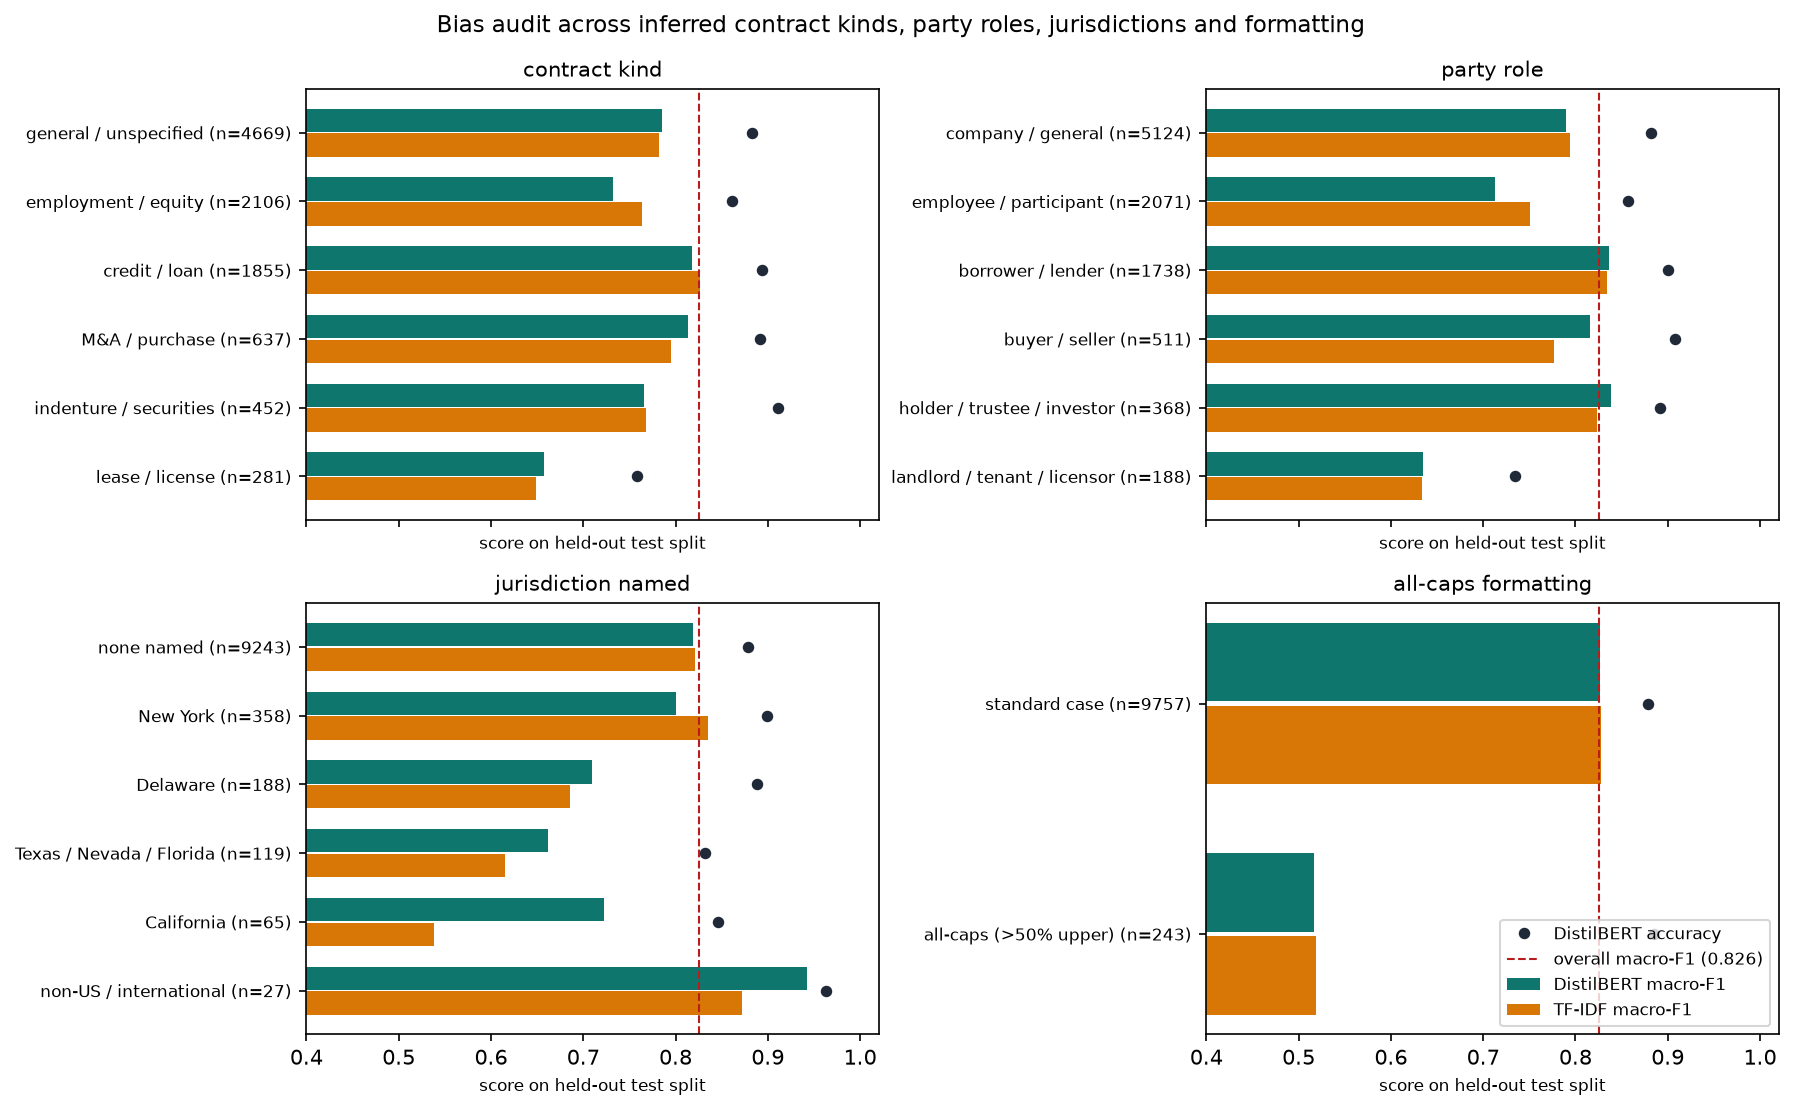

In [9]:
train_slices = data.bias_slices(full["train"]["text"])
test_slices = data.bias_slices(full["test"]["text"])
topk_path = RESULTS / "retrieval" / "tfidf" / "topk_test.npz"
p10_test = None
if topk_path.exists():
    pos_test = np.load(topk_path)["positions"]
    y_bank = np.asarray(full["train"]["label"])
    p10_test = (y_bank[pos_test] == y_test[:, None])[:, :10].mean(axis=1)

audit_frames = {}
for dim, g_test in test_slices.items():
    g_train = train_slices[dim]
    df = metrics.f1_by_group(y_test, pred, g_test, cfg.n_classes).set_index("group")
    df.insert(1, "train_share", [float(np.mean(g_train == k)) for k in df.index])
    if B10 in test:
        df["lora_macro_f1"] = metrics.f1_by_group(
            y_test, test[B10]["y_pred"], g_test, cfg.n_classes
        ).set_index("group")["macro_f1"]
    if "tfidf" in test:
        df["tfidf_macro_f1"] = metrics.f1_by_group(
            y_test, test["tfidf"]["y_pred"], g_test, cfg.n_classes
        ).set_index("group")["macro_f1"]
    if p10_test is not None:
        df["retrieval_p10"] = [float(p10_test[g_test == k].mean()) for k in df.index]
    audit_frames[dim] = df.sort_values("n", ascending=False)

audit = pd.concat(audit_frames)
audit.index.names = ["dimension", "group"]
if not cfg.fast_run:
    (REPORTS / "bias_audit.md").write_text(runs.to_markdown(audit.reset_index()))
fig = plots.plot_bias_slices(
    audit,
    overall_f1=metrics.macro_f1_score(y_test, pred, cfg.n_classes),
    path=None if cfg.fast_run else REPORTS / "figures" / "bias_audit_slices.png",
)
audit.round(4)

→ **Consequence:** four structural biases emerge across contracts, parties, jurisdictions and typography:
1. **Under-represented contract types and party roles (*lease / license*, *landlord / tenant / licensor*):**
   SEC Exhibit-10 filings are dominated by corporate financing (*credit / loan*, 21 % of train, 0.818 macro-F1,
   89.4 % accuracy) and executive plans (*employment / equity*, 18.2 % of train). Commercial leases and IP
   licenses account for only 2.5 % of training clauses (1.6 % naming a *landlord, tenant or licensor*): on
   these slices accuracy drops by 14–17 points to **75.8 %** (*lease / license*, macro-F1 **0.657**, retrieval
   P@10 **0.576**) and **73.4 %** (*landlord / tenant / licensor*, macro-F1 **0.634**, retrieval P@10 **0.529**).
2. **Employment & equity plans vs financing agreements:** *employment / equity* clauses (2 106 test clauses)
   reach 86.1 % accuracy but 0.732 macro-F1 because LEDGAR's main near-synonym confusion pairs (*Tax
   Withholdings* / *Withholdings* and *Defined Terms* / *Definitions*) concentrate in incentive and stock-option
   plans.
3. **Jurisdictions named:** on clauses naming *California* (65 test clauses, 0.9 % of train), DistilBERT keeps
   **0.723 macro-F1** (84.6 % accuracy) while the TF-IDF baseline drops to **0.538 macro-F1** (−18.5 points).
   Clauses naming *Delaware* (0.710 macro-F1, 88.8 % accuracy) or *Texas / Nevada / Florida* (0.662 macro-F1)
   concentrate in the *Governing Laws* / *Applicable Laws* and *Submission* / *Consent To Jurisdiction* /
   *Venues* confusion clusters.
4. **ALL-CAPS conspicuous boilerplate (> 50 % uppercase, 243 test clauses):** accuracy is 88.5 % because most
   uppercase clauses belong to *Waiver Of Jury Trials*, *Warranties* or *Governing Laws*, but **macro-F1 across
   the 29 types that appear in ALL-CAPS falls to 0.517** (0.519 for TF-IDF): uncased tokenization erases
   typographic emphasis and pulls rare uppercase clauses toward those dominant boilerplate classes.

## 6. What do the errors look like?

Twenty misclassified test clauses from the three most confused pairs, with the probability the model gave to
its (wrong) answer.

In [10]:
probs = pd.read_csv(RESULTS / CANDIDATE / "pred_test.csv")["prob_max"].to_numpy()
rng = np.random.default_rng(cfg.seed)
shown = []
for a, b in confused[["class_a", "class_b"]].head(3).to_numpy():
    wrong = np.flatnonzero(((y_test == a) & (pred == b)) | ((y_test == b) & (pred == a)))
    shown += list(rng.choice(wrong, size=min(7, len(wrong)), replace=False))
errors = pd.DataFrame(
    {
        "true": [LABELS[y_test[i]] for i in shown],
        "predicted": [LABELS[pred[i]] for i in shown],
        "prob": probs[shown],
        "clause": [full["test"][int(i)]["text"][:220] + "…" for i in shown],
    }
)
errors.head(20)

,true,predicted,prob,clause
0,Governing Laws,Applicable Laws,0.8209,The Plan shall be governed by and construed in accordance with the laws of the State of Oklahoma except as supersede...
1,Governing Laws,Applicable Laws,0.9840,"Except to the extent superseded by laws of the United States, the laws of Texas will be controlling in all matters r..."
2,Applicable Laws,Governing Laws,0.9758,"This Agreement is entered into under, and governed for all purposes by, the laws of the State of Texas, without rega..."
3,Applicable Laws,Governing Laws,0.9713,"THIS AMENDMENT AGREEMENT SHALL BE GOVERNED BY, AND CONSTRUED IN ACCORDANCE WITH, THE LAWS OF THE STATE OF NEW YORK.…"
4,Applicable Laws,Governing Laws,0.9226,These Terms and Conditions shall be governed by and construed in accordance with the law of the State of Delaware re...
5,Applicable Laws,Governing Laws,0.9624,"This Agreement shall be construed and governed in accordance with the laws of the State of New York, without giving ..."
6,Applicable Laws,Governing Laws,0.8417,"The validity, construction, interpretation and effect of this Grant shall be governed by and construed in accordance..."
7,Tax Withholdings,Withholdings,0.6511,The Subsidiary under whose payroll the Participant is registered shall have the right to deduct or withhold from the...
8,Tax Withholdings,Withholdings,0.6283,"At the time of any tax withholding event under the Plan, the Participant shall make adequate provision for the Tax-R..."
9,Tax Withholdings,Withholdings,0.9968,"The Company or any Parent or Subsidiary shall have the authority and the right to deduct or withhold, or require a P..."


→ **Consequence:** most errors are disagreements about the label, not misreadings: the *Applicable Laws* clauses predicted as
*Governing Laws* are governing-law clauses in all but their label, and the model is sure of itself (probabilities
often above 0.9). For use, two consequences: for these groups the type should be shown as the group ("governing /
applicable law") or confirmed by a reviewer; and a high probability is no guarantee, so confidence alone must not
decide which clauses skip human review (the model grows over-confident with training, `04_finetune_distilbert`).

## Files written

`reports/final_table.md`, `reports/bias_audit.md`, `reports/comparisons/*.json` (one file per paired
comparison), `reports/figures/test_confusion_pairs.png`, `reports/figures/bias_audit_slices.png`. The model
card (`reports/model_card.md`) takes its numbers from here.